In [49]:
import pandas as pd

data_frame= pd.read_csv("train.csv")

In [50]:
data_frame

,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake M...,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are ...,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation or...",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as ...,1
...,...,...,...,...,...
7608,10869,NaN,NaN,Two giant cranes holding a bridge collapse int...,1
7609,10870,NaN,NaN,@aria_ahrary @TheTawniest The out of control w...,1
7610,10871,NaN,NaN,M1.94 [01:04 UTC]?5km S of Volcano Hawaii. htt...,1
7611,10872,NaN,NaN,Police investigating after an e-bike collided ...,1


## 1° Consulta

**Hipótesis:** los tweets escritos en **primera persona** (*I*, *I'm*, *my*, *me*) tienden a ser de **lenguaje figurado**.

La idea es que quien habla de sí mismo suele estar contando una experiencia personal o exagerando una situación cotidiana ("I'm dying", "my life is a disaster"). En cambio, quien reporta una emergencia real tiende a usar un tono impersonal, como el de una noticia ("Fire in downtown...", "Earthquake hits...").

Para comprobarlo, separamos los tweets en dos grupos (con y sin primera persona) y comparamos qué porcentaje de cada grupo corresponde a emergencias reales y cuál a lenguaje figurado.

In [51]:
# \b marca limite de palabra: evita que "me" coincida dentro de "meeting"
data_frame["primera persona"] = data_frame["text"].str.contains(
    r"\b(?:i|i'm|im|my|me)\b", case=False, regex=True
)

resumen = data_frame.groupby("primera persona")["target"].agg(
    cantidad="count", emergencia_real="mean"
)
resumen["emergencia_real"] = resumen["emergencia_real"] * 100
resumen["lenguaje_figurado"] = 100 - resumen["emergencia_real"]
resumen = resumen.rename(columns={
    "cantidad": "Cantidad de tweets",
    "emergencia_real": "Emergencia real (%)",
    "lenguaje_figurado": "Lenguaje figurado (%)",
})
resumen.index = resumen.index.map({True: "Con primera persona", False: "Sin primera persona"})

resumen

,Cantidad de tweets,Emergencia real (%),Lenguaje figurado (%)
primera persona,,,
Sin primera persona,5788,49.395301,50.604699
Con primera persona,1825,22.575342,77.424658


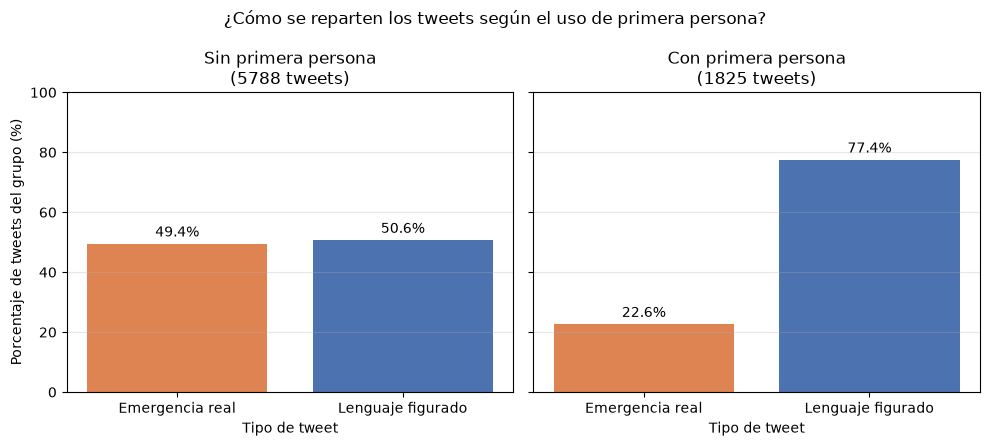

In [52]:
import matplotlib.pyplot as plt

# un gráfico por grupo: dentro de cada uno, real + figurado suman 100%
tipos = ["Emergencia real", "Lenguaje figurado"]
colores = ["#DD8452", "#4C72B0"]

fig, ejes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)

for ax, grupo in zip(ejes, ["Sin primera persona", "Con primera persona"]):
    valores = [resumen.loc[grupo, "Emergencia real (%)"], resumen.loc[grupo, "Lenguaje figurado (%)"]]
    barras = ax.bar(tipos, valores, color=colores)
    ax.bar_label(barras, fmt="%.1f%%", padding=3)
    ax.set_title(f"{grupo}\n({resumen.loc[grupo, 'Cantidad de tweets']} tweets)")
    ax.set_xlabel("Tipo de tweet")
    ax.set_ylim(0, 100)
    ax.grid(axis="y", alpha=0.3)

ejes[0].set_ylabel("Porcentaje de tweets del grupo (%)")
fig.suptitle("¿Cómo se reparten los tweets según el uso de primera persona?")
fig.tight_layout()

plt.show()

**Conclusión:** la hipótesis se confirma con claridad.

- De los tweets escritos en **primera persona**, solo el **22,6%** describe una emergencia real, mientras que el **77,4%** es lenguaje figurado
- De los tweets **sin primera persona**, la proporción queda prácticamente pareja: **49,4%** emergencia real contra **50,6%** lenguaje figurado.


## 2° Consulta

**Hipótesis:** los tweets de **emergencia real** (**target** = 1) son, en promedio, **más largos** que los de **lenguaje figurado** (**target** = 0).

La idea es que, al informar una emergencia real, el autor necesita incluir datos concretos (el lugar, el tipo de incidente, las consecuencias), lo que genera un texto más extenso. En cambio, en el lenguaje figurado alcanza con una palabra de desastre usada como adjetivo o para enfatizar una situación.

Para comprobarlo, calculamos el largo de cada tweet en caracteres y comparamos sus estadísticas descriptivas según el **target**. Además, medimos la correlación entre el largo y el **target**.

In [53]:
data_frame["largo de tweet"] = data_frame["text"].str.len()
Agrupar=data_frame.groupby("target")["largo de tweet"].describe()
Agrupar


,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
0,4342.0,95.706817,35.885924,7.0,68.0,101.0,130.0,157.0
1,3271.0,108.113421,29.309854,14.0,88.0,115.0,136.0,151.0


In [54]:
data_frame[["target", "largo de tweet"]].corr()

,target,largo de tweet
target,1.000000,0.181817
largo de tweet,0.181817,1.000000


**Conclusión:** la hipótesis se confirma en la dirección esperada, pero no en magnitud.

- **Promedio:** los tweets de emergencia real tienen en promedio **108,1** caracteres, contra **95,7** de los de lenguaje figurado. Es decir, son algo más largos.
- **Dispersión:** los desvíos estándar son de **29,3** (emergencia real) y **35,9** (lenguaje figurado). Ambos son mucho más grandes que la diferencia entre los promedios (unos 12 caracteres), por lo que dentro de cada grupo hay tweets de todos los largos.
- **Cuartiles:** el 50% central de los tweets de emergencia real mide entre **88** y **136** caracteres, un rango que cae casi entero dentro del **68-130** del lenguaje figurado. Los dos grupos se superponen en gran medida.
- **Correlación:** la correlación entre el largo y el **target** es de **0,18**, lo que indica una relación débil. Elevada al cuadrado, significa que el largo explica solo alrededor del **3%** de la variación en el tipo de tweet.

En resumen, el largo del tweet es una señal real pero secundaria: conocer cuánto mide un tweet casi no ayuda a saber si es real o figurado. Para distinguir los dos grupos hay que analizar **qué** dice el tweet, no **cuánto** mide.

### Visualización: distribución del largo según el tipo de tweet

Un **boxplot** muestra en una sola figura la mediana (línea negra), el 50% central de los datos (la caja, del cuartil 1 al 3) y el rango total (los bigotes). Es el gráfico adecuado para comparar distribuciones y ver si se superponen, que es justamente lo que analizamos en esta consulta.

/tmp/ipykernel_11785/162026176.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  cajas = ax.boxplot(largos, vert=False, patch_artist=True, widths=0.5,


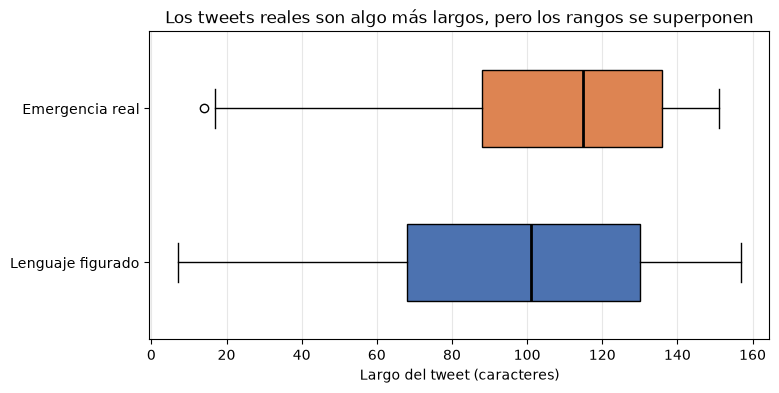

In [55]:
import matplotlib.pyplot as plt

largos = [
    data_frame.loc[data_frame["target"] == 0, "largo de tweet"],
    data_frame.loc[data_frame["target"] == 1, "largo de tweet"],
]

fig, ax = plt.subplots(figsize=(8, 4))
cajas = ax.boxplot(largos, vert=False, patch_artist=True, widths=0.5,
                   medianprops={"color": "black", "linewidth": 2})
for caja, color in zip(cajas["boxes"], ["#4C72B0", "#DD8452"]):
    caja.set_facecolor(color)

ax.set_yticks([1, 2], ["Lenguaje figurado", "Emergencia real"])
ax.set_xlabel("Largo del tweet (caracteres)")
ax.set_title("Los tweets reales son algo más largos, pero los rangos se superponen")
ax.grid(axis="x", alpha=0.3)

plt.show()

La caja de emergencia real está corrida hacia la derecha (tweets más largos), pero se superpone casi por completo con la de lenguaje figurado. Esto confirma visualmente la conclusión: el largo es una señal real pero débil.

## 3° Consulta

Seguimos buscando relaciones entre columnas. En este caso queremos ver si la **keyword** de un tweet se relaciona con su **target**, es decir, si hay palabras clave que aparecen casi siempre en emergencias reales y otras que aparecen casi siempre en lenguaje figurado.

In [56]:
data_frame["keyword"].unique()

<StringArray>
[                  nan,              'ablaze',            'accident',
          'aftershock', 'airplane%20accident',           'ambulance',
         'annihilated',        'annihilation',          'apocalypse',
          'armageddon',
 ...
             'weapons',           'whirlwind',        'wild%20fires',
            'wildfire',           'windstorm',             'wounded',
              'wounds',               'wreck',            'wreckage',
             'wrecked']
Length: 222, dtype: str

Al ejecutar la consulta vemos que la columna **keyword** tiene **222** valores distintos.

**Hipótesis:** algunas keywords de desastre se usan mayormente en sentido figurado. Por ejemplo, **accident** puede referirse a un error cotidiano ("it was an **accident**") y no a una emergencia real, sino a una equivocación humana.

Para comprobarlo, calculamos el **ratio de emergencia real por keyword**: el promedio del **target** para cada keyword. Como el **target** vale 0 o 1, ese promedio es directamente la proporción de tweets de emergencia real. Un valor cercano a 1 indica que la keyword se usa casi siempre en emergencias reales, y uno cercano a 0, que se usa casi siempre en sentido figurado.

In [57]:
promedio_emergencia_segun_keyword=data_frame.groupby("keyword")["target"].agg(['mean','count'])
promedio_emergencia_segun_keyword.nlargest(7,"mean")

,mean,count
keyword,,
debris,1.000000,37
derailment,1.000000,39
wreckage,1.000000,39
outbreak,0.975000,40
oil%20spill,0.973684,38
typhoon,0.973684,38
suicide%20bombing,0.969697,33


**Resultado (keywords más asociadas a emergencias reales):** *debris*, *derailment* y *wreckage* tienen un ratio de **1**, es decir, el **100%** de sus tweets son emergencias reales. Les siguen *outbreak*, *oil spill*, *typhoon* y *suicide bombing*, todas por encima del **96%**.

Son palabras que describen hechos concretos y específicos (escombros, descarrilamientos, derrames de petróleo, tifones), que difícilmente se usan en sentido figurado. Cuando un tweet contiene alguna de estas keywords, casi con seguridad habla de una emergencia real.

In [58]:
promedio_emergencia_segun_keyword.nsmallest(7,"mean")

,mean,count
keyword,,
aftershock,0.000000,34
body%20bags,0.024390,41
ruin,0.027027,37
blazing,0.029412,34
body%20bag,0.030303,33
electrocute,0.031250,32
screaming,0.055556,36


**Resultado (keywords más asociadas al lenguaje figurado):** *aftershock* tiene un ratio de **0**, es decir, ninguno de sus tweets es una emergencia real. Le siguen *body bags*, *ruin*, *blazing*, *body bag* y *electrocute*, todas por debajo del **4%**, y *screaming*, con menos del **6%**.

Son palabras que, aunque suenan a desastre, se usan mayormente para exagerar o expresar emociones ("this ruined my day", "I'm screaming"). Cuando un tweet contiene alguna de estas keywords, casi con seguridad usa lenguaje figurado.

Por último, buscamos las keywords **ambiguas**: aquellas que no permiten distinguir entre emergencia real y lenguaje figurado porque se usan en ambos sentidos por igual.

Para encontrarlas, calculamos qué tan lejos está el ratio de cada keyword del **0,5** (la mitad exacta) y nos quedamos con las más cercanas. Solo consideramos keywords con al menos 20 tweets, para que el ratio no dependa de unos pocos casos.

In [59]:
promedio_emergencia_segun_keyword["distancia_a_0.5"] = (promedio_emergencia_segun_keyword["mean"] - 0.5).abs()

# solo keywords con al menos 20 apariciones, para que el ratio no dependa de pocos casos
keywords_frecuentes = promedio_emergencia_segun_keyword[promedio_emergencia_segun_keyword["count"] >= 20]

ambiguas = keywords_frecuentes.nsmallest(10, "distancia_a_0.5")
ambiguas

,mean,count,distancia_a_0.5
keyword,,,
bombed,0.500000,38,0.000000
explosion,0.512821,39,0.012821
hail,0.514286,35,0.014286
storm,0.514286,35,0.014286
derail,0.485714,35,0.014286
rescued,0.485714,35,0.014286
hijack,0.484848,33,0.015152
lightning,0.515152,33,0.015152
hostage,0.483871,31,0.016129


**Conclusión:** cuanto más cerca del **0,5** está el ratio de una keyword, más ambigua es, porque se reparte por igual entre emergencias reales y lenguaje figurado. Por eso ordenamos por la distancia a ese valor.

- **bombed** es totalmente ambigua: su ratio es exactamente **0,5**, por lo que no se inclina hacia ninguno de los dos tipos de tweet.
- **explosion** sigue un camino muy parecido, con un ratio apenas por encima de 0,5.

Estas keywords, por sí solas, no aportan información para saber si un tweet describe una emergencia real o usa lenguaje figurado.

## 4° Consulta

El campo **text** de los tweets incluye menciones a otros usuarios (con **@**) y enlaces (con **https://...**).

**Hipótesis:**
- Los tweets con **URL** tienden a ser **emergencias reales**, porque el enlace suele adjuntar una noticia sobre el hecho.
- Los tweets con **@** tienden a ser **lenguaje figurado**, porque la mención suele dirigirse a un amigo, en un tono informal o humorístico.

Para comprobarlo, calculamos primero qué proporción de los tweets con URL son emergencias reales, y después qué proporción de los tweets con menciones son de lenguaje figurado.

In [60]:
#primero nos fijamos que proporcion de URL son de emergecia real

Solo_url = data_frame[
    data_frame["text"].str.contains(r"https?://", na=False)
]

Solo_url_emergencia = Solo_url[
    Solo_url["target"] == 1
]

proporcion_emergencia = (
    Solo_url_emergencia.shape[0] / Solo_url.shape[0] #con shape[0] obtengo las cantidad de fillas de un data_frame 
) * 100

proporcion_emergencia


54.696549987408716

In [61]:
Proporcion_lenguaje_figurado=100-float(proporcion_emergencia)
Proporcion_lenguaje_figurado

45.303450012591284

**Resultado (URL):** aproximadamente el **54,7%** de los tweets que contienen un enlace (http o https) son de emergencia real, y el **45,3%** restante es de lenguaje figurado.

La hipótesis se cumple en la dirección esperada: entre los tweets con URL predominan las emergencias reales, aunque por un margen moderado.

Ahora calculamos qué proporción de los tweets con menciones (**@**) son de lenguaje figurado.

In [62]:
#cuantos menciones por tweet

Solo_menciones = data_frame[data_frame["text"].str.contains("@")]

Solo_menciones_target_figurado= Solo_menciones[Solo_menciones ["target"]==
                                               0]

proporcion_mencion_lenguaje_figurado = (

    Solo_menciones_target_figurado.shape[0]/Solo_menciones.shape[0]


)*100

proporcion_mencion_lenguaje_figurado

66.84649337910741

In [63]:
proporcion_mencion_emergencia = 100 - proporcion_mencion_lenguaje_figurado
proporcion_mencion_emergencia

33.153506620892585

**Resultado (@):** el **67%** de los tweets con **@** son de lenguaje figurado, y solo el **33%** son de emergencia real.

Esta hipótesis se cumple con claridad. La suposición partía de que las menciones se hacen a otras personas, muchas veces con un fin humorístico o informal. Con estos datos no podemos justificar que el motivo sea ese, pero sí podemos afirmar que las menciones se asocian fuertemente con el lenguaje figurado: 2 de cada 3 tweets con **@** lo son.

Aun así, 1 de cada 3 tweets con mención es una emergencia real, por lo que la mención es una tendencia clara, no una regla.

## 5° Consulta

Hasta ahora trabajamos con las columnas **target**, **text** y **keyword**. Queda una columna sin analizar: **location**.

**Hipótesis:** la columna **location** tiene muchos valores nulos, y esa ausencia se relaciona con el tipo de tweet. En particular, esperamos que quien informa una emergencia real complete su ubicación con más frecuencia, por lo que entre los tweets **sin** ubicación deberían predominar los de lenguaje figurado.

Para comprobarlo, tomamos los tweets sin **location** y calculamos qué porcentaje corresponde a cada tipo.

In [64]:
# Cobertura de location por tipo de tweet

location_escrita = data_frame[data_frame["location"].isna()]
proporcion_por_target = (
    location_escrita["target"]
    .value_counts(normalize=True)
    .rename({
        0: "Lenguaje figurado",
        1: "Emergencia real"
    })
    * 100
)

proporcion_por_target




target
Lenguaje figurado    57.560205
Emergencia real      42.439795
Name: proportion, dtype: float64

**Resultado:** entre los tweets **sin** ubicación, el **57,6%** es de lenguaje figurado y el **42,4%** es de emergencia real.

A simple vista, esto parece ir en la dirección de la hipótesis, porque los tweets sin ubicación son mayormente figurados. Sin embargo, este resultado por sí solo no alcanza para confirmarla: para saber si la falta de ubicación realmente se relaciona con el tipo de tweet, habría que comparar esta distribución con la de los tweets que **sí** tienen ubicación. Si ambas son parecidas, la ausencia de **location** no aportaría información sobre el **target**.

# SPARK


In [65]:
#creamos spark session
from pyspark.sql import SparkSession
spark= SparkSession.builder.getOrCreate()

##vamos a ver como leer datos 



### Carga de datos en un RDD

Leemos el CSV y convertimos cada fila en un diccionario, para poder trabajar las consultas con transformaciones y acciones de Spark.

In [66]:
import csv
import io

# wholeTextFiles trae el archivo completo (no linea por linea), necesario porque
# algunos tweets tienen saltos de linea dentro del campo text (CSV con comillas)
archivo_completo = spark.sparkContext.wholeTextFiles("train.csv").map(lambda x: x[1]).collect()[0]

filas = list(csv.reader(io.StringIO(archivo_completo)))
header = filas[0]
filas_rdd = spark.sparkContext.parallelize(filas[1:])

tweets_rdd = filas_rdd.map(lambda fila: {
    "id": fila[0],
    "keyword": fila[1] if fila[1] != "" else None,
    "location": fila[2] if fila[2] != "" else None,
    "text": fila[3],
    "target": int(fila[4]),
})

In [67]:
tweets_rdd.take(5)

[{'id': '1',
  'keyword': None,
  'location': None,
  'text': 'Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all',
  'target': 1},
 {'id': '4',
  'keyword': None,
  'location': None,
  'text': 'Forest fire near La Ronge Sask. Canada',
  'target': 1},
 {'id': '5',
  'keyword': None,
  'location': None,
  'text': "All residents asked to 'shelter in place' are being notified by officers. No other evacuation or shelter in place orders are expected",
  'target': 1},
 {'id': '6',
  'keyword': None,
  'location': None,
  'text': '13,000 people receive #wildfires evacuation orders in California ',
  'target': 1},
 {'id': '7',
  'keyword': None,
  'location': None,
  'text': 'Just got sent this photo from Ruby #Alaska as smoke from #wildfires pours into a school ',
  'target': 1}]

## 6° Consulta

**Hipótesis:** los tweets sobre emergencias reales incluyen números con más frecuencia que los de lenguaje figurado.

La idea es que, al reportar un hecho real, se suelen dar datos concretos: cifras de víctimas, direcciones, fechas u horarios. Para comprobarlo, separamos los tweets que contienen al menos un dígito de los que no, y calculamos la proporción de cada tipo en ambos grupos.

In [68]:
import re

In [69]:
tweets_con_numero = tweets_rdd.filter(lambda x: bool(re.search(r"\d", x["text"])))

conteo_por_target = (
    tweets_con_numero
    .map(lambda x: (x["target"], 1))
    .reduceByKey(lambda a, b: a + b)
    .collectAsMap()
)

total = sum(conteo_por_target.values())
proporcion_emergencia = conteo_por_target[1] / total
proporcion_emergencia


0.523756906077348

In [70]:
tweets_sin_numero = tweets_rdd.filter(lambda x: not re.search(r"\d", x["text"]))

conteo_por_target = (
    tweets_sin_numero
    .map(lambda x: (x["target"], 1))
    .reduceByKey(lambda a, b: a + b)
    .collectAsMap()
)

total = sum(conteo_por_target.values())
Proporcion_lenguaje_figurado = conteo_por_target[0] / total
Proporcion_lenguaje_figurado


0.7082253886010362

**Conclusión:** la hipótesis se confirma.

- Entre los tweets **con** números, el **52,4%** son emergencias reales.
- Entre los tweets **sin** números, el **70,8%** son lenguaje figurado; es decir, solo el **29,2%** son emergencias reales.

Tener un número en el texto hace que la proporción de emergencias reales pase de menos de un tercio a algo más de la mitad. La tendencia va claramente en la dirección esperada. Sin embargo, como entre los tweets con números la proporción queda cerca del 50%, la presencia de un número no alcanza por sí sola para clasificar un tweet como emergencia real.

## 7° Consulta

**Hipótesis:** los tweets con signos de exclamación o de pregunta (**!** o **?**) tienden a ser de lenguaje figurado. Estos signos expresan emoción, sorpresa o exageración, algo típico de una conversación informal. En cambio, un reporte de emergencia real suele tener un tono más neutro e informativo.

Para comprobarlo, separamos los tweets con y sin estos signos y calculamos qué proporción de cada grupo corresponde a emergencias reales.

In [79]:
# clave compuesta (tiene signos, target) -> countByKey cuenta cuántos tweets hay de cada combinación
conteo = (
    tweets_rdd
    .map(lambda x: (("!" in x["text"] or "?" in x["text"], x["target"]), 1))
    .countByKey()
)
print(dict(conteo))  # ej: (True, 1) = tweets con signos que son emergencia real

proporcion_con_signos = conteo[(True, 1)] / (conteo[(True, 0)] + conteo[(True, 1)])
proporcion_sin_signos = conteo[(False, 1)] / (conteo[(False, 0)] + conteo[(False, 1)])

proporcion_con_signos, proporcion_sin_signos

{(False, 1): 2808, (True, 0): 1183, (False, 0): 3159, (True, 1): 463}


(0.28128797083839613, 0.47058823529411764)

**Conclusión:** la hipótesis se confirma.

- De los tweets **con** **!** o **?**, solo el **28,1%** describe una emergencia real.
- De los tweets **sin** estos signos, el **47,1%** describe una emergencia real.

Usar signos de exclamación o pregunta baja la proporción de emergencias reales en unos **19 puntos**: el tono emocional se asocia claramente con el lenguaje figurado. Aun así, más de 1 de cada 4 tweets con estos signos es una emergencia real, así que es una tendencia, no una regla.

## 8° Consulta

**Hipótesis:** el vocabulario más frecuente es claramente distinto entre los tweets de emergencia real y los de lenguaje figurado, más allá de las keywords que ya trae el dataset.

Para comprobarlo, contamos las palabras más repetidas en cada tipo de tweet y comparamos ambos rankings.

Al hacer un primer conteo, vemos que las palabras más repetidas son casi todas **stopwords**: preposiciones, artículos, pronombres, conjunciones y verbos auxiliares. Estas palabras aparecen con mucha frecuencia en cualquier texto en inglés, sin importar el tema, así que no aportan información.

Por eso armamos una lista de stopwords y las filtramos, para que el ranking muestre palabras con un significado relevante.

In [72]:
stopwords = {"the", "a", "an", "to", "of", "in", "on", "at", "is", "are", "was",
             "i", "you", "it", "for", "and", "or", "this", "that", "my", "with",
             "be", "as", "by", "from", "have", "has", "it's", "im", "me", "so",
             "but", "more", "no", "who", "will", "up", "like", "just", "your",
             "not", "i'm", "out", "if", "all", "over", "via", "after",
             "we", "when", "he", "she", "they", "about", "how", "what", "can",
             "do", "don't", "one", "new", "get", "??", "...", "than", "into",
             "been", "our", "their", "his", "her", "its", "us", "them", "would",
             "could", "should", "there", "here", "now", "im"}


In [73]:
#empezamos por el target1
emergencia_tweets = tweets_rdd.filter(lambda x: x["target"] == 1)
palabras= emergencia_tweets.flatMap(lambda x: x["text"].lower().replace("&amp;", "&").split(" ")).filter(lambda palabra: palabra not in stopwords and len(palabra) > 1).map(lambda x: (x,1)).reduceByKey(lambda a,b: a+b)
palabras.takeOrdered(15,key=lambda x:-x[1])

[('fire', 150),
 ('suicide', 103),
 ('disaster', 97),
 ('police', 93),
 ('people', 93),
 ('killed', 92),
 ('california', 88),
 ('families', 81),
 ('were', 72),
 ('two', 71),
 ('train', 71),
 ('storm', 69),
 ('bomb', 66),
 ('emergency', 65),
 ('crash', 64)]

In [74]:
#vamos son lenguaje figurado
figurado_tweets = tweets_rdd.filter(lambda x: x["target"] == 0)
palabras= figurado_tweets.flatMap(lambda x: x["text"].lower().replace("&amp;", "&").split(" ")).filter(lambda palabra: palabra not in stopwords and len(palabra) > 1).map(lambda x: (x,1)).reduceByKey(lambda a,b: a+b)
palabras.takeOrdered(15,key=lambda x:-x[1])

[('body', 106),
 ('love', 84),
 ('why', 83),
 ('got', 82),
 ('full', 81),
 ('people', 81),
 ('know', 77),
 ('see', 77),
 ('video', 76),
 ('back', 75),
 ('emergency', 75),
 ('going', 73),
 ('????', 73),
 ('some', 71),
 ('still', 70)]

**Conclusión:** la hipótesis se confirma.

- En los tweets de **emergencia real** dominan palabras ligadas a hechos concretos y sus consecuencias: *fire*, *suicide*, *disaster*, *police*, *killed*, *storm* o *bomb*.
- En los tweets de **lenguaje figurado** aparecen palabras de la conversación cotidiana: *love*, *why*, *video*, *going* o *still*.

El vocabulario de los dos grupos es claramente distinto: los tweets reales hablan de lo que pasó, mientras que los figurados hablan de la vida diaria del autor.

### Visualización: vocabulario de cada tipo de tweet

En un **gráfico de dispersión**, cada punto es una de las 25 palabras más frecuentes del dataset. Su posición indica cuántas veces aparece en tweets de emergencia real (eje horizontal) y en tweets de lenguaje figurado (eje vertical). La línea punteada marca las palabras que aparecen lo mismo en ambos grupos: cuanto más lejos de ella está un punto, más característica es la palabra de un solo tipo de tweet.

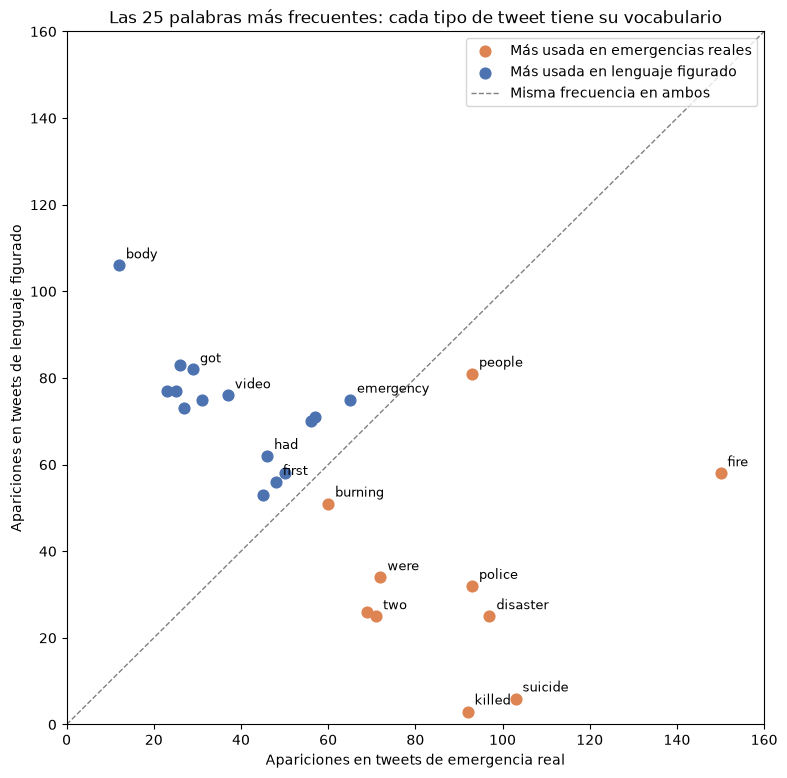

In [75]:
import matplotlib.pyplot as plt

# conteo de palabras por target, sin stopwords (misma limpieza que en la 8° consulta)
palabras = (
    data_frame.assign(palabra=data_frame["text"].str.lower().str.replace("&amp;", "&").str.split(" "))
    .explode("palabra")
)
palabras = palabras[
    ~palabras["palabra"].isin(stopwords)
    & (palabras["palabra"].str.len() > 1)
    & palabras["palabra"].str.contains("[a-z]")  # descarta tokens sin letras como "????"
]
frecuencias = palabras.groupby(["palabra", "target"]).size().unstack(fill_value=0)
frecuencias.columns = ["figurado", "real"]
top = frecuencias.assign(total=frecuencias.sum(axis=1)).nlargest(25, "total")

es_real = top["real"] > top["figurado"]

fig, ax = plt.subplots(figsize=(9, 9))
ax.scatter(top.loc[es_real, "real"], top.loc[es_real, "figurado"], color="#DD8452", s=60, label="Más usada en emergencias reales")
ax.scatter(top.loc[~es_real, "real"], top.loc[~es_real, "figurado"], color="#4C72B0", s=60, label="Más usada en lenguaje figurado")

limite = top[["real", "figurado"]].max().max() + 10
ax.plot([0, limite], [0, limite], color="gray", linestyle="--", linewidth=1, label="Misma frecuencia en ambos")

# etiqueto de la más frecuente a la menos, salteando las que quedarían pegadas a otra ya etiquetada
etiquetadas = []
for palabra, fila in top.iterrows():
    punto = (fila["real"], fila["figurado"])
    if all(abs(punto[0] - x) > 10 or abs(punto[1] - y) > 5 for x, y in etiquetadas):
        ax.annotate(palabra, punto, xytext=(5, 5), textcoords="offset points", fontsize=9)
        etiquetadas.append(punto)

ax.set_xlim(0, limite)
ax.set_ylim(0, limite)
ax.set_xlabel("Apariciones en tweets de emergencia real")
ax.set_ylabel("Apariciones en tweets de lenguaje figurado")
ax.set_title("Las 25 palabras más frecuentes: cada tipo de tweet tiene su vocabulario")
ax.legend(loc="upper right")

plt.show()

Las palabras se separan en dos grupos bien diferenciados, a cada lado de la diagonal. Debajo quedan las de emergencia real (*fire*, *suicide*, *killed*, *police*, *disaster*) y arriba las de lenguaje figurado (*body*, *got*, *video*). Solo unas pocas, como *emergency* o *burning*, quedan cerca de la línea y se usan en ambos sentidos. Esto confirma que el vocabulario de los dos tipos de tweet es claramente distinto.

## 9° Consulta

**Hipótesis:** quien reporta una emergencia real usa hashtags con más frecuencia, para que el tweet sea encontrado y se difunda. En el lenguaje figurado, el hashtag sería menos frecuente o cumpliría otro rol.

Para comprobarlo, separamos los tweets con y sin hashtag (**#**) y calculamos qué proporción de cada grupo corresponde a emergencias reales.

In [76]:
# una sola pasada: la clave es si tiene hashtag y el valor (target, 1)
# reduceByKey acumula (suma de targets, cantidad) y mapValues calcula la proporción
proporcion_por_hashtag = (
    tweets_rdd
    .map(lambda x: ("#" in x["text"], (x["target"], 1)))
    .reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1]))
    .mapValues(lambda v: v[0] / v[1])
    .collectAsMap()
)

proporcion_con_hashtag_emergencia_real = proporcion_por_hashtag[True]
proporcion_sin_hashtag_emergenca_real = proporcion_por_hashtag[False]

proporcion_con_hashtag_emergencia_real, proporcion_sin_hashtag_emergenca_real

(0.49687677455990914, 0.4094326725905673)

**Conclusión:** la hipótesis se confirma en la dirección esperada, pero la señal es débil.

- De los tweets **con** hashtag, el **49,7%** describe una emergencia real.
- De los tweets **sin** hashtag, el **40,9%** describe una emergencia real.

Tener un hashtag se asocia con una proporción de emergencias reales casi **9 puntos** más alta. Sin embargo, incluso entre los tweets con hashtag, los reales no llegan a la mitad: el grupo queda prácticamente repartido 50/50 entre emergencia real y lenguaje figurado.

Por eso, el hashtag es una señal débil que por sí sola no alcanza para distinguir una emergencia real de un uso figurado.

## Visualización resumen: características del texto

A lo largo del trabajo analizamos varias características del texto de los tweets por separado. Este **mapa de calor** las reúne en una sola figura: cada celda muestra el porcentaje de emergencias reales entre los tweets que tienen (o no tienen) cada característica.

El color indica hacia dónde se inclina cada grupo: **azul** si predomina el lenguaje figurado, **naranja** si predomina la emergencia real y **gris** si queda mitad y mitad.

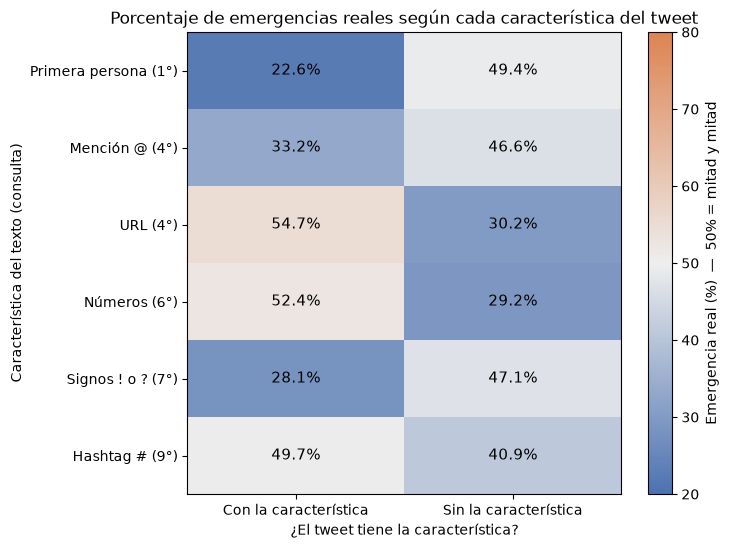

In [77]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

# mismas condiciones que en las consultas anteriores
texto = data_frame["text"]
caracteristicas = {
    "Primera persona (1°)": texto.str.contains(r"\b(?:i|i'm|im|my|me)\b", case=False, regex=True),
    "Mención @ (4°)": texto.str.contains("@"),
    "URL (4°)": texto.str.contains(r"https?://"),
    "Números (6°)": texto.str.contains(r"\d"),
    "Signos ! o ? (7°)": texto.str.contains(r"[!?]"),
    "Hashtag # (9°)": texto.str.contains("#"),
}

tabla = pd.DataFrame({
    nombre: {
        "Con": data_frame.loc[tiene, "target"].mean() * 100,
        "Sin": data_frame.loc[~tiene, "target"].mean() * 100,
    }
    for nombre, tiene in caracteristicas.items()
}).T

# azul = mayoría figurado, gris = mitad y mitad, naranja = mayoría real
paleta = LinearSegmentedColormap.from_list("figurado_real", ["#4C72B0", "#EEEEEE", "#DD8452"])

fig, ax = plt.subplots(figsize=(7, 6))
imagen = ax.imshow(tabla, cmap=paleta, norm=TwoSlopeNorm(vmin=20, vcenter=50, vmax=80), aspect="auto")

for fila in range(tabla.shape[0]):
    for columna in range(tabla.shape[1]):
        ax.text(columna, fila, f"{tabla.iloc[fila, columna]:.1f}%", ha="center", va="center", fontsize=11)

ax.set_xticks([0, 1], ["Con la característica", "Sin la característica"])
ax.set_yticks(range(len(tabla)), tabla.index)
ax.set_xlabel("¿El tweet tiene la característica?")
ax.set_ylabel("Característica del texto (consulta)")
ax.set_title("Porcentaje de emergencias reales según cada característica del tweet")
fig.colorbar(imagen, ax=ax, label="Emergencia real (%)  —  50% = mitad y mitad")

plt.show()

El mapa permite comparar todas las señales de un vistazo:

- Las características que más empujan hacia el **lenguaje figurado** son la **primera persona** (22,6% de reales) y los **signos ! o ?** (28,1%), seguidas por las **menciones @** (33,2%).
- Las que más empujan hacia la **emergencia real** son las **URL** (54,7%) y los **números** (52,4%). Aun así, ninguna supera por mucho el 50%.
- El **hashtag** es la señal más débil: con o sin él, el porcentaje queda cerca de la mitad.

En resumen, el texto tiene señales más fuertes para reconocer el lenguaje figurado que para confirmar una emergencia real.

# Conclusiones principales

El objetivo del dataset es detectar automáticamente si un tweet habla de una **emergencia real** o si usa palabras de desastre en **sentido figurado**. A partir del análisis exploratorio llegamos a las siguientes conclusiones:

**1. La keyword es la señal más fuerte.** Hay keywords que casi determinan el tipo de tweet: *debris*, *derailment* y *wreckage* son 100% emergencias reales, mientras que *aftershock* es 0%. Sin embargo, otras como *bombed* o *explosion* son totalmente ambiguas, así que la keyword por sí sola no alcanza (3° consulta).

**2. El vocabulario del texto distingue claramente los dos grupos.** Los tweets reales hablan de hechos y consecuencias (*fire*, *killed*, *police*, *disaster*), y los figurados, de la vida cotidiana del autor (*love*, *body*, *video*) (8° consulta).

**3. El lenguaje figurado se reconoce mejor que la emergencia real.** Las señales más fuertes apuntan hacia lo figurado:
- **Primera persona:** solo el 22,6% de los tweets que la usan son reales (1° consulta).
- **Signos ! o ?:** 28,1% de reales (7° consulta).
- **Menciones @:** 33,2% de reales (4° consulta).

En cambio, las señales de emergencia real (**URL** con 54,7% y **números** con 52,4%) apenas superan la mitad (4° y 6° consultas).

**4. Algunas características aportan poco.** El **largo** del tweet tiene una correlación de solo 0,18 con el tipo (2° consulta), el **hashtag** deja los grupos casi mitad y mitad (9° consulta), y la **ubicación** no alcanza para confirmar una relación con el tipo de tweet (5° consulta).

**En síntesis:** ninguna característica aislada alcanza para clasificar un tweet con seguridad. Pero varias señales débiles o moderadas apuntan en direcciones consistentes: un tweet impersonal, con URL, números y vocabulario de hechos concretos tiende a ser una emergencia real, mientras que uno en primera persona, con signos emocionales y menciones tiende a ser figurado.
